# Examine Features
This jupyter notebook assumes you have already processed the images found in ``data/sitters/`` into the ``features.pkl`` file.

In [1]:
import pandas as pd
import numpy as np
import os

historical_features = pd.read_pickle(r'../data2/features_historical.pkl')
historical_features.head()

# keep only existing files
historical_features['full_path'] = '../data2/historical_sitters/' + historical_features['folder'] + '/' + historical_features['filename'] + '.jpg'

# I removed some wrongly processed images in the folder, remove them from the feature dataframe:
historical_features = historical_features[historical_features['full_path'].apply(os.path.exists)].copy()

# drop helper column
historical_features.drop(columns='full_path', inplace=True)
len(historical_features['folder'].unique())

210

In [6]:
import copy
import pandas as pd
import numpy as np
import os

features = pd.read_pickle(r'../results/features.pkl')
features.head()

# features.pkl was extracted before some faces were removed by hand from data/sitters/
# (duplicates, low quality, mismatched sitters). results/face_list_paper.csv lists the faces
# that remained and were used in the paper; keep only those rows.
face_list = pd.read_csv('../results/face_list_paper.csv', dtype=str)
keep = pd.MultiIndex.from_frame(face_list[['folder', 'filename']])
features2 = features[pd.MultiIndex.from_frame(features[['folder', 'filename']]).isin(keep)].copy()

print("Original rows:", len(features))
print("Cleaned rows:", len(features2))
print("Removed rows:", len(features) - len(features2))
print("Unique images", len(features2['folder'].unique()))

rkd_features = copy.copy(features2)
filtered_df = features2[features2['folder'].duplicated(keep=False)]
rkd_features2 = filtered_df

print("Removed rows:", len(rkd_features) - len(rkd_features2))
print("multi-face images", len(rkd_features2['folder'].unique()))

print("Total rows in single-face images:", len(rkd_features))
print("Unique folders in single-face images:", len(rkd_features['folder'].unique()))

print("Total rows in multi-face images:", len(rkd_features2))
print("Unique folders in multi-face images:", len(rkd_features2['folder'].unique()))

Original rows: 1884
Cleaned rows: 1859
Removed rows: 25
Unique images 1725
Removed rows: 1654
multi-face images 71
Total rows in single-face images: 1859
Unique folders in single-face images: 1725
Total rows in multi-face images: 205
Unique folders in multi-face images: 71


In [7]:
########### Summary Statistics ###########

# Total faces
total_faces = len(features2)

# Single-face identities (folders with exactly 1 image)
single_face_mask = ~features2['folder'].duplicated(keep=False)
single_face_faces = single_face_mask.sum()
single_face_identities = features2[single_face_mask]['folder'].nunique()

# Multi-face identities (folders with more than 1 image)
multi_face_faces = len(rkd_features2)
multi_face_identities = len(rkd_features2['folder'].unique())

print("=" * 60)
print("FACE RECOGNITION DATASET SUMMARY")
print("=" * 60)
print(f"Total faces in dataset:              {total_faces}")
print(f"\nFaces with single-image identities: {single_face_faces}")
print(f"  └─ Number of identities:           {single_face_identities}")
print(f"\nFaces with multi-image identities:  {multi_face_faces}")
print(f"  └─ Number of identities:           {multi_face_identities}")
print("=" * 60)
print(f"Verification: {single_face_faces} + {multi_face_faces} = {single_face_faces + multi_face_faces}")
print("=" * 60)


FACE RECOGNITION DATASET SUMMARY
Total faces in dataset:              1859

Faces with single-image identities: 1654
  └─ Number of identities:           1654

Faces with multi-image identities:  205
  └─ Number of identities:           71
Verification: 1654 + 205 = 1859


In [3]:
########### Leave One Out ###########
"""
This snippet calculates the leave one out validation technique
We stack the embeddings (the feature vectors in features.pkl) and use the cosine_similarity metric to calculate the angle between the vectors to evaluate the similarity.
This is then used to calculate the False Positive Rate (FPR), True Positive Rate (TPR) for several thresholds.
"""
def leave_one_out_from_df(df: pd.DataFrame):
    genuine_scores = []
    imposter_scores = []

    for idx, row in df.iterrows():
        probe_id = row["folder"]
        probe_feat = row["feature"].reshape(1, -1)

        # Genuine comparisons (same identity, exclude self)
        genuine_feats = df[(df["folder"] == probe_id) & (df.index != idx)]["feature"]
        if len(genuine_feats) > 0:
            g_scores = cosine_similarity(probe_feat, np.vstack(genuine_feats))[0]
            genuine_scores.extend(g_scores)

        # Imposter comparisons (different identity)
        imposter_feats = df[df["folder"] != probe_id]["feature"]
        if len(imposter_feats) > 0:
            i_scores = cosine_similarity(probe_feat, np.vstack(imposter_feats))[0]
            imposter_scores.extend(i_scores)

    return np.array(genuine_scores), np.array(imposter_scores)


In [4]:
########### Get the metrics Historical Portraits ###########
"""
This snippet stacks the embeddings (the feature vectors in features.pkl), normalizes the and uses the cosine_similarity metric to calculate the angle between the vectors to evaluate the similarity.
This is then used to calculate the False Positive Rate (FPR), True Positive Rate (TPR) for several thresholds.
"""

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from sklearn.preprocessing import normalize
from sklearn.metrics import roc_curve, auc

historical_embeddings = np.stack(historical_features['feature'].values).squeeze(1)
historical_embeddings = normalize(historical_embeddings, norm='l2')
historical_similarity_matrix = cosine_similarity(historical_embeddings)  # shape (N, N)
print("Size Similarity Matrix Historical Portraits:", historical_similarity_matrix.shape)

historical_identities = historical_features['folder'].values
historical_identity_matrix = np.equal.outer(historical_identities, historical_identities).astype(int)  # (N, N)

i, j = np.triu_indices_from(historical_similarity_matrix, k=1)

historical_similarities = historical_similarity_matrix[i, j]        # similarity scores
historical_labels = historical_identity_matrix[i, j]

# Calculate
h_genuine, h_imposter = leave_one_out_from_df(historical_features)

# Compute EER
h_y_true = np.concatenate([np.ones_like(h_genuine), np.zeros_like(h_imposter)])
h_y_scores = np.concatenate([h_genuine, h_imposter])
h_fpr, h_tpr, h_thresholds = roc_curve(h_y_true, h_y_scores)
print("FPR:", h_fpr)
print("TPR:", h_tpr)
print("Thresholds:", h_thresholds)
h_eer_idx = np.nanargmin(np.abs(h_fpr - (1 - h_tpr)))
h_eer = h_fpr[h_eer_idx]
print("EER:", h_eer)


Size Similarity Matrix Historical Portraits: (764, 764)
FPR: [0.00000000e+00 3.44927496e-06 6.89854992e-06 ... 9.99865478e-01
 9.99868928e-01 1.00000000e+00]
TPR: [0.0000000e+00 6.4516129e-04 6.4516129e-04 ... 1.0000000e+00 1.0000000e+00
 1.0000000e+00]
Thresholds: [        inf  1.0000001   0.9684812  ... -0.15497941 -0.155018
 -0.20925556]
EER: 0.1460388526331765


In [5]:

########### Get the metrics RKD ###########
"""
This snippet stacks the embeddings (the feature vectors in features.pkl), normalizes the and uses the cosine_similarity metric to calculate the angle between the vectors to evaluate the similarity.
This is then used to calculate the False Positive Rate (FPR), True Positive Rate (TPR) for several thresholds.
"""

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from sklearn.preprocessing import normalize
from sklearn.metrics import roc_curve, auc

rkd_embeddings = np.stack(rkd_features['feature'].values).squeeze(1)
rkd_embeddings = normalize(rkd_embeddings, norm='l2')
rkd_similarity_matrix = cosine_similarity(rkd_embeddings)  # shape (N, N)
print("Size Similarity Matrix Historical Portraits:", rkd_similarity_matrix.shape)

rkd_identities = rkd_features['folder'].values
rkd_identity_matrix = np.equal.outer(rkd_identities, rkd_identities).astype(int)  # (N, N)

i, j = np.triu_indices_from(rkd_similarity_matrix, k=1)

rkd_similarities = rkd_similarity_matrix[i, j]        # similarity scores
rkd_labels = rkd_identity_matrix[i, j]

# Calculate
rkd_genuine, rkd_imposter = leave_one_out_from_df(rkd_features)

# Compute EER
rkd_y_true = np.concatenate([np.ones_like(rkd_genuine), np.zeros_like(rkd_imposter)])
rkd_y_scores = np.concatenate([rkd_genuine, rkd_imposter])
rkd_fpr, rkd_tpr, rkd_thresholds = roc_curve(rkd_y_true, rkd_y_scores)
print("FPR:", rkd_fpr)
print("TPR:", rkd_tpr)
print("Thresholds:", rkd_thresholds)
rkd_eer_idx = np.nanargmin(np.abs(rkd_fpr - (1 - rkd_tpr)))
rkd_eer = rkd_fpr[rkd_eer_idx]
print("EER:", rkd_eer)



Size Similarity Matrix Historical Portraits: (1859, 1859)
FPR: [0.         0.         0.         ... 0.99905194 0.99905252 1.        ]
TPR: [0.         0.00309598 0.00619195 ... 1.         1.         1.        ]
Thresholds: [        inf  0.9159976   0.8991011  ... -0.15992722 -0.15993139
 -0.30445445]
EER: 0.1300281232046554


In [6]:

########### Get the metrics RKD ###########
"""
This snippet stacks the embeddings (the feature vectors in features.pkl), normalizes the and uses the cosine_similarity metric to calculate the angle between the vectors to evaluate the similarity.
This is then used to calculate the False Positive Rate (FPR), True Positive Rate (TPR) for several thresholds.
"""

from sklearn.metrics.pairwise import cosine_similarity
import numpy as np
from sklearn.preprocessing import normalize
from sklearn.metrics import roc_curve, auc

rkd2_embeddings = np.stack(rkd_features2['feature'].values).squeeze(1)
rkd2_embeddings = normalize(rkd2_embeddings, norm='l2')
rkd2_similarity_matrix = cosine_similarity(rkd2_embeddings)  # shape (N, N)
print("Size Similarity Matrix Historical Portraits:", rkd2_similarity_matrix.shape)

rkd2_identities = rkd_features2['folder'].values
rkd2_identity_matrix = np.equal.outer(rkd2_identities, rkd2_identities).astype(int)  # (N, N)

i, j = np.triu_indices_from(rkd2_similarity_matrix, k=1)

rkd2_similarities = rkd2_similarity_matrix[i, j]        # similarity scores
rkd2_labels = rkd2_identity_matrix[i, j]

# Calculate
rkd2_genuine, rkd2_imposter = leave_one_out_from_df(rkd_features2)

# Compute EER
rkd2_y_true = np.concatenate([np.ones_like(rkd2_genuine), np.zeros_like(rkd2_imposter)])
rkd2_y_scores = np.concatenate([rkd2_genuine, rkd2_imposter])
rkd2_fpr, rkd2_tpr, rkd2_thresholds = roc_curve(rkd2_y_true, rkd2_y_scores)
print("FPR:", rkd2_fpr)
print("TPR:", rkd2_tpr)
print("Thresholds:", rkd2_thresholds)
rkd2_eer_idx = np.nanargmin(np.abs(rkd2_fpr - (1 - rkd2_tpr)))
rkd2_eer = rkd2_fpr[rkd2_eer_idx]
print("EER:", rkd2_eer)



Size Similarity Matrix Historical Portraits: (205, 205)
FPR: [0.         0.         0.         ... 0.98659348 0.98664206 1.        ]
TPR: [0.         0.00309598 0.00619195 ... 1.         1.         1.        ]
Thresholds: [        inf  0.9159976   0.8991011  ... -0.09266739 -0.09271369
 -0.23339413]
EER: 0.1315393209306844


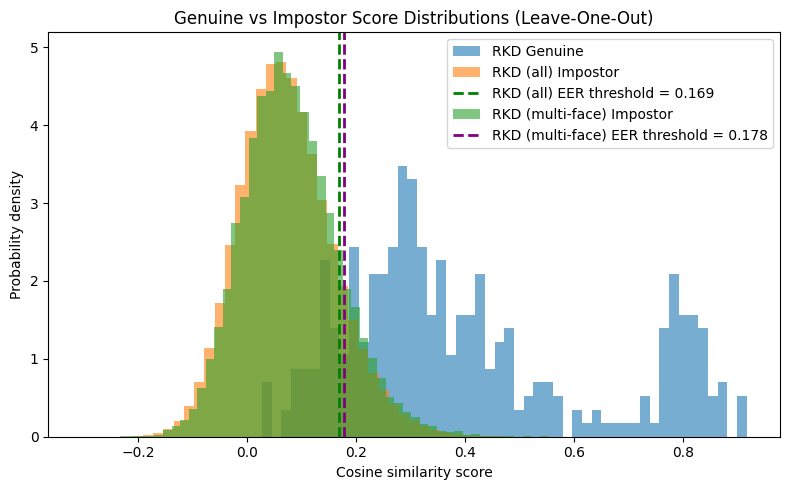

In [19]:
import matplotlib.pyplot as plt

# --- Toggle datasets ---
show_historical = False
show_rkd_all = True
show_rkd_multi = True
# ----------------------

plt.figure(figsize=(8, 5))

# --- Genuine scores ---
# The genuine scores for RKD (all) and RKD (multi-face) are from the same
# multi-face identity pairs, so only one genuine histogram is needed.
if show_historical:
    h_eer_threshold = h_thresholds[h_eer_idx]
    plt.hist(h_genuine, bins=50, density=True, alpha=0.6, label="Historical Portraits Genuine")

if show_rkd_all and show_rkd_multi:
    # Genuine is the same for both — plot once
    plt.hist(rkd2_genuine, bins=50, density=True, alpha=0.6, label="RKD Genuine")
elif show_rkd_all:
    plt.hist(rkd_genuine, bins=50, density=True, alpha=0.6, label="RKD (all) Genuine")
elif show_rkd_multi:
    plt.hist(rkd2_genuine, bins=50, density=True, alpha=0.6, label="RKD (multi-face) Genuine")

# --- Impostor scores ---
if show_historical:
    plt.hist(h_imposter, bins=50, density=True, alpha=0.6, label="Historical Portraits Impostor")
    plt.axvline(h_eer_threshold, linestyle="--", linewidth=2, color='red',
                label=f"Historical Portraits EER threshold = {h_eer_threshold:.3f}")

if show_rkd_all:
    rkd_eer_threshold = rkd_thresholds[rkd_eer_idx]
    plt.hist(rkd_imposter, bins=50, density=True, alpha=0.6, label="RKD (all) Impostor")
    plt.axvline(rkd_eer_threshold, linestyle="--", linewidth=2, color='green',
                label=f"RKD (all) EER threshold = {rkd_eer_threshold:.3f}")

if show_rkd_multi:
    rkd2_eer_threshold = rkd2_thresholds[rkd2_eer_idx]
    plt.hist(rkd2_imposter, bins=50, density=True, alpha=0.6, label="RKD (multi-face) Impostor")
    plt.axvline(rkd2_eer_threshold, linestyle="--", linewidth=2, color='purple',
                label=f"RKD (multi-face) EER threshold = {rkd2_eer_threshold:.3f}")

plt.xlabel("Cosine similarity score")
plt.ylabel("Probability density")
plt.title("Genuine vs Impostor Score Distributions (Leave-One-Out)")
plt.legend()
plt.grid(False)
plt.tight_layout()
plt.savefig(os.path.join('../figures', f"combined_genuine_vs_impostor_score_distribution3.png"))
plt.show()


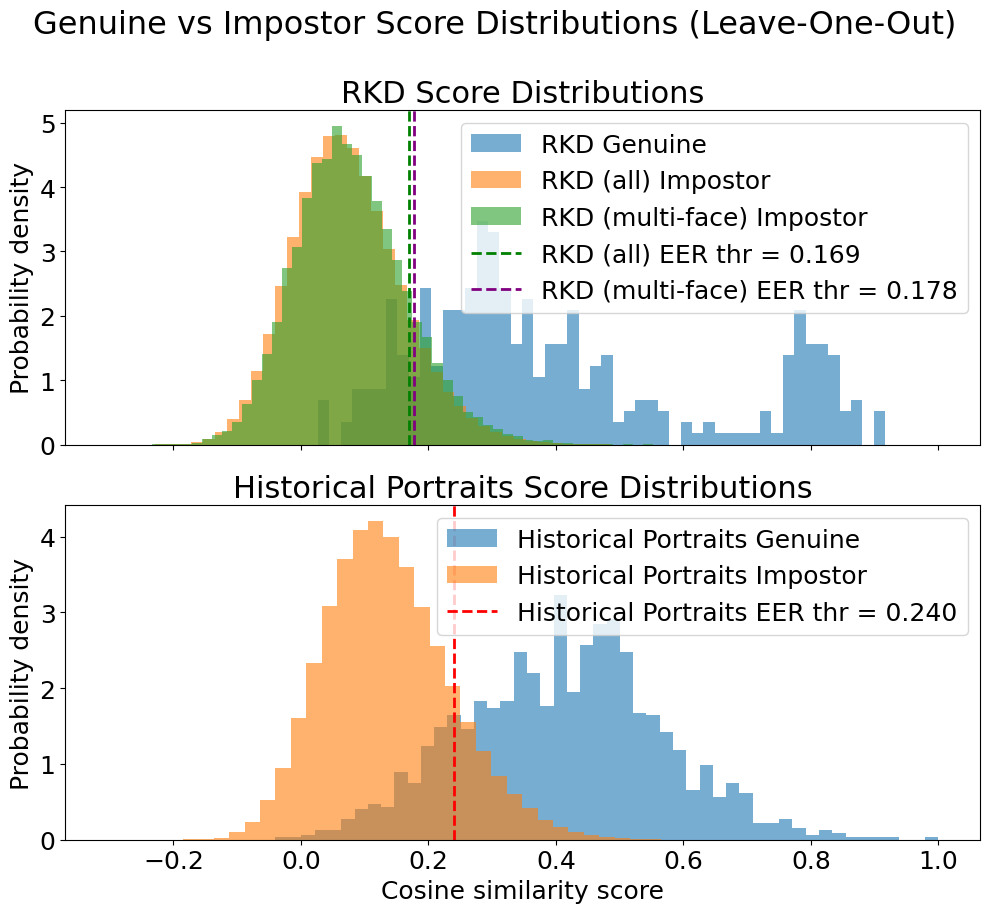

In [21]:
import matplotlib.pyplot as plt

FONTSIZE = 18
TITLE_FONTSIZE = 22

fig, (ax_rkd, ax_hist) = plt.subplots(2, 1, figsize=(10, 9), sharex=True)

# --- Top: RKD ---
rkd_eer_threshold = rkd_thresholds[rkd_eer_idx]
rkd2_eer_threshold = rkd2_thresholds[rkd2_eer_idx]

# Genuine is the same for both RKD variants — plot once
ax_rkd.hist(rkd2_genuine, bins=50, density=True, alpha=0.6, label="RKD Genuine")
ax_rkd.hist(rkd_imposter, bins=50, density=True, alpha=0.6, label="RKD (all) Impostor")
ax_rkd.hist(rkd2_imposter, bins=50, density=True, alpha=0.6, label="RKD (multi-face) Impostor")
ax_rkd.axvline(rkd_eer_threshold, linestyle="--", linewidth=2, color='green',
               label=f"RKD (all) EER thr = {rkd_eer_threshold:.3f}")
ax_rkd.axvline(rkd2_eer_threshold, linestyle="--", linewidth=2, color='purple',
               label=f"RKD (multi-face) EER thr = {rkd2_eer_threshold:.3f}")
ax_rkd.set_ylabel("Probability density", fontsize=FONTSIZE)
ax_rkd.set_title("RKD Score Distributions", fontsize=TITLE_FONTSIZE)
ax_rkd.legend(fontsize=FONTSIZE)
ax_rkd.tick_params(axis='both', labelsize=FONTSIZE)
ax_rkd.grid(False)

# --- Bottom: Historical Portraits ---
h_eer_threshold = h_thresholds[h_eer_idx]

ax_hist.hist(h_genuine, bins=50, density=True, alpha=0.6, label="Historical Portraits Genuine")
ax_hist.hist(h_imposter, bins=50, density=True, alpha=0.6, label="Historical Portraits Impostor")
ax_hist.axvline(h_eer_threshold, linestyle="--", linewidth=2, color='red',
                label=f"Historical Portraits EER thr = {h_eer_threshold:.3f}")
ax_hist.set_xlabel("Cosine similarity score", fontsize=FONTSIZE)
ax_hist.set_ylabel("Probability density", fontsize=FONTSIZE)
ax_hist.set_title("Historical Portraits Score Distributions", fontsize=TITLE_FONTSIZE)
ax_hist.legend(fontsize=FONTSIZE)
ax_hist.tick_params(axis='both', labelsize=FONTSIZE)
ax_hist.grid(False)

plt.suptitle("Genuine vs Impostor Score Distributions (Leave-One-Out)", fontsize=TITLE_FONTSIZE + 1, y=1.01)
plt.tight_layout()
plt.savefig(os.path.join('../figures', "subplots_genuine_vs_impostor_score_distribution.png"), bbox_inches='tight')
plt.show()


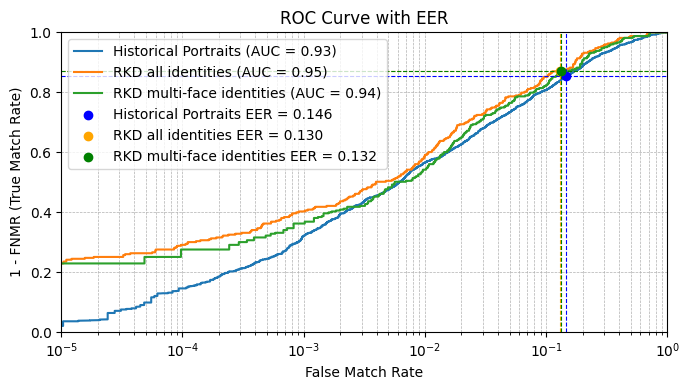

In [28]:
from matplotlib import pyplot as plt

# Compute FNMR (False Non-Match Rate)
h_fnmr = 1 - h_tpr
h_roc_auc = auc(h_fpr, h_tpr)

rkd_fnmr = 1 - rkd_tpr
rkd_roc_auc = auc(rkd_fpr, rkd_tpr)

rkd2_fnmr = 1 - rkd2_tpr
rkd2_roc_auc = auc(rkd2_fpr, rkd2_tpr)

plt.figure(figsize=(7,4))

# Plot FMR (x) vs 1 - FNMR (y), i.e. TPR
plt.plot(h_fpr, 1 - h_fnmr, label=f'Historical Portraits (AUC = {h_roc_auc:.2f})')
plt.plot(rkd_fpr, 1 - rkd_fnmr, label=f'RKD all identities (AUC = {rkd_roc_auc:.2f})')
plt.plot(rkd2_fpr, 1 - rkd2_fnmr, label=f'RKD multi-face identities (AUC = {rkd2_roc_auc:.2f})')


# Plot chance line (random performance)
# plt.plot([1e-6, 1], [0, 1], 'k--', label='Chance')

# Plot EER point
plt.scatter(h_fpr[h_eer_idx], 1 - h_fnmr[h_eer_idx],
            c='blue', zorder=5, label=f'Historical Portraits EER = {h_eer:.3f}')
plt.axvline(h_fpr[h_eer_idx], color='blue', linestyle='--', linewidth=0.8)
plt.axhline(1 - h_fnmr[h_eer_idx], color='blue', linestyle='--', linewidth=0.8)

plt.scatter(rkd_fpr[rkd_eer_idx], 1 - rkd_fnmr[rkd_eer_idx],
            c='orange', zorder=5, label=f'RKD all identities EER = {rkd_eer:.3f}')
plt.axvline(rkd_fpr[rkd_eer_idx], color='orange', linestyle='--', linewidth=0.8)
plt.axhline(1 - rkd_fnmr[rkd_eer_idx], color='orange', linestyle='--', linewidth=0.8)

plt.scatter(rkd2_fpr[rkd2_eer_idx], 1 - rkd2_fnmr[rkd2_eer_idx],
            c='green', zorder=5, label=f'RKD multi-face identities EER = {rkd2_eer:.3f}')
plt.axvline(rkd2_fpr[rkd2_eer_idx], color='green', linestyle='--', linewidth=0.8)
plt.axhline(1 - rkd2_fnmr[rkd2_eer_idx], color='green', linestyle='--', linewidth=0.8)

# Axis settings
plt.xscale('log')
plt.xlim([1e-5, 1])   # log scale needs strictly positive values
plt.ylim([0, 1])

plt.xlabel('False Match Rate')
plt.ylabel('1 - FNMR (True Match Rate)')
plt.title('ROC Curve with EER')
plt.legend()
plt.grid(True, which="both", ls="--", linewidth=0.5)
plt.tight_layout()
plt.savefig(os.path.join('../figures', f"combined_log_roc_curve_with_EER2.png"))
plt.show()

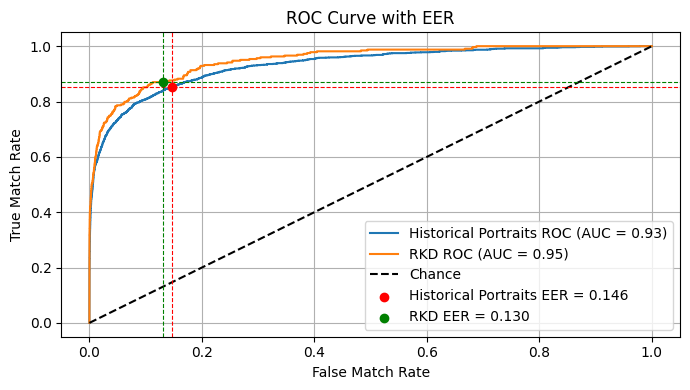

In [26]:
plt.figure(figsize=(7, 4))
plt.plot(h_fpr, h_tpr, label=f'Historical Portraits ROC (AUC = {h_roc_auc:.2f})')
plt.plot(rkd_fpr, rkd_tpr, label=f'RKD ROC (AUC = {rkd_roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='Chance')

# Plot EER point
plt.scatter(h_fpr[h_eer_idx], h_tpr[h_eer_idx], c='red', zorder=5, label=f'Historical Portraits EER = {h_eer:.3f}')
plt.axvline(h_fpr[h_eer_idx], color='red', linestyle='--', linewidth=0.8)
plt.axhline(h_tpr[h_eer_idx], color='red', linestyle='--', linewidth=0.8)

plt.scatter(rkd_fpr[rkd_eer_idx], rkd_tpr[rkd_eer_idx], c='green', zorder=5, label=f'RKD EER = {rkd_eer:.3f}')
plt.axvline(rkd_fpr[rkd_eer_idx], color='green', linestyle='--', linewidth=0.8)
plt.axhline(rkd_tpr[rkd_eer_idx], color='green', linestyle='--', linewidth=0.8)

plt.xlabel('False Match Rate')
plt.ylabel('True Match Rate')
plt.title('ROC Curve with EER')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(os.path.join('../figures', f"combined_roc_curve_with_EER2.png"))
plt.show()

In [27]:
# Target FARs (false accept rates)
target_fars = [0.00001, 0.00005, 0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1]   # 0.01%, 0.1%, 1%, 10%

results = []
for target_fpr in target_fars:
    idxs = np.where(fpr <= target_fpr)[0]
    if len(idxs) > 0:
        best_idx = idxs[np.argmax(tpr[idxs])]
        results.append({
            "FAR": target_fpr,
            "#False Matches": target_fpr*194,
            "TAR": tpr[best_idx],
            "FNMR": 1 - tpr[best_idx],
            "Threshold": thresholds[best_idx]
        })
    else:
        results.append({
            "FAR": target_fpr,
            "TAR": None,
            "Threshold": None
        })

df_results = pd.DataFrame(results)
print(df_results)

NameError: name 'fpr' is not defined

In [ ]:
print(tpr)
print(fpr)

# Target FAR
target_fpr = 0.1

# Find all thresholds where FPR <= 0.001
indices = np.where(fpr <= target_fpr)[0]

# Choose the one with highest TPR (best trade-off)
best_idx = indices[np.argmax(tpr[indices])]

# Threshold at FAR = 0.1%
threshold_at_far = thresholds[best_idx]
preds = (similarities >= threshold_at_far).astype(int)

from sklearn.metrics import accuracy_score

acc = accuracy_score(labels, preds)
print(f'Accuracy at FAR = {target_fpr*100:.2f}%: {acc*100:.2f}%')

# T-SNE Evaluation
T-SNE can be used to find clusters in high dimensional data. This is purely a visualization tool.

In [ ]:
# import matplotlib.pyplot as plt
# import seaborn as sns
# from sklearn.manifold import TSNE
#
# df = filtered_df2 # Only the multi-face sitters
#
# feature_emb = np.stack(df['feature'].values).squeeze(1)
# # print(feature_emb.shape, type(feature_emb))
# # print(feature_emb)
#
#
# metrics = TSNE(n_components=2).fit_transform(norm_embeddings)
# sorting = np.argsort(df['folder'].values)
# new_labels = np.array([f'id {label}' for label in df['folder'].values.astype(int)])[sorting]
# tsnex = np.array(metrics[:, 0])[sorting]
# tsney = np.array(metrics[:, 1])[sorting]
#
# df = pd.DataFrame([new_labels, tsnex, tsney], index=['label', 'tsne_x', 'tsne_y'])
#
# df = df.transpose()
# plt.figure()
# g = sns.scatterplot(x='tsne_x', y='tsne_y', hue='label', palette="rainbow", data=df)
# g.legend(loc='center left', bbox_to_anchor=(1, 0.5), title="painting id's")
# plt.title(f't-SNE')

# Similarity Matrix
Shows the faces that are classified the same for a certain threshold. The identities on the diagonal are the same.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity
import matplotlib.pyplot as plt
import seaborn as sns

df = historical_features
df.head()
#
# identities = df['folder'].values
# print(len(identities))
# embeddings = np.stack(df['feature'].values).squeeze(1)
# similarity_matrix = cosine_similarity(embeddings)
# print(similarity_matrix)
#
# # thresh = 0.5
# # similarity_matrix[similarity_matrix <= thresh] = 0
# # similarity_matrix[similarity_matrix > thresh] = 1
# fig, ax = plt.subplots(figsize=(10,10))
# sns.heatmap(similarity_matrix, linewidths=.5, ax=ax)

# Creating folder with similarity pairs above threshold